In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Math, display
sp.init_printing()

In [2]:
def fancy_display(before_text, latex, after_text=r'', latexer=sp.latex, mather=Math):
    """
    For example, 
    fancy_display(r'E = ', E, r',')
    """
    if mather is None:
        mather  = lambda i: i
    if latexer is None:
        latexer  = lambda i: i
    display(mather(before_text + latexer(latex) + after_text))

## Задание 1

> На поверхности с первой квадратичной формой
>    $$ \mathrm{d} s^2 = \mathrm{d} u^2 + \operatorname{sh}^2 u\; \mathrm{d} v^2 $$
> найдите длину дуги линии $u = v$ между точками $M_1 (u_1, v_1)$ и $M_2 (u_2, v_2)$.

In [3]:
u, v, t = sp.symbols('u,v,t')
E, F, G = sp.symbols('E,F,G')

In [4]:
E = sp.Lambda((u, v), 1)
F = sp.Lambda((u, v), 0)
G = sp.sinh(u) ** 2

# Параметризация кривой
u_func = t
v_func = t

fancy_display(r'E = ', E, r',')
fancy_display(r'F = ', F, r',')
fancy_display(r'G = ', G, r'.')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [5]:
du = u_func.diff(t)
dv = v_func.diff(t)

E_sub = E(t, t)
F_sub = F(t, t)
G_sub = G.subs({u: t, v: t})

u1, u2 = sp.symbols("u_1,u_2")

root = sp.sqrt(E_sub * du**2 + 2 * F_sub * du * dv + G_sub * dv**2).simplify()

Integral = sp.integrate(root, (t, u1, u2))

fancy_display(r'Длина  = ', Integral.simplify(), r'.')

<IPython.core.display.Math object>

## Задание 2

> На сфере задан прямоугольный треугольник, сторонами которого являются дуги больших окружностей сферы. Найдите:
> + соотношение между сторонами треугольника;
> + его площадь.


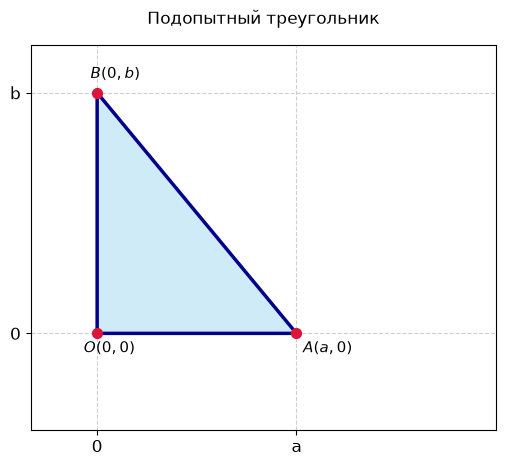

In [6]:
# ~~ Вставка от Google Gemini ~~

# 1. Choose arbitrary but mathematically sound values to guarantee a right triangle
a = 1
c = 2
d = 4.5
b = 4

# 2. Define the vertices based on the formulas
A = (a, c)
B = (b, c)
C = (a, d)

# Extract X and Y coordinates for plotting (closing the loop back to A)
x_coords = [A[0], B[0], C[0], A[0]]
y_coords = [A[1], B[1], C[1], A[1]]

plt.figure(figsize=(6, 5))

# 3. Plot the triangle sides
plt.plot(x_coords, y_coords, color='darkblue', linewidth=2.5, zorder=2)
plt.fill(x_coords, y_coords, color='skyblue', alpha=0.4)

# 4. Plot the vertices as distinct points
plt.scatter([a, b, a], [c, c, d], color='crimson', s=50, zorder=3)

# 5. Label the vertices with their algebraic forms
plt.text(a - 0.2, c - 0.2, "$O (0, 0)$", fontsize=11, fontweight='bold')
plt.text(b + 0.1, c - 0.2, "$A (a, 0)$", fontsize=11, fontweight='bold')
plt.text(a - 0.1, d + 0.15, "$B (0, b)$", fontsize=11, fontweight='bold')

# 6. Customize the axes to show the symbols instead of numbers
plt.xticks([a, b], ['0', 'a'], fontsize=12)
plt.yticks([c, d], ['0', 'b'], fontsize=12)

# Set limits and grid lines for clean aesthetics
plt.xlim(0, 7)
plt.ylim(1, 5)
plt.grid(True, linestyle='--', alpha=0.6)
plt.title("Подопытный треугольник", fontsize=12, pad=15)

plt.show()

In [7]:
def calc_length(curve, E, F, G, t_1, t_2):
    ru = curve[0]
    rv = curve[1]
    
    du = ru.diff(t)
    dv = rv.diff(t)

    E_sub = E.subs({phi: ru, psi: rv})
    F_sub = F.subs({phi: ru, psi: rv})
    G_sub = G.subs({phi: ru, psi: rv})
    
    length = sp.integrate(sp.sqrt(E_sub * du**2 + 2 * F_sub * du * dv + G_sub * dv**2), (t, t_1, t_2))
    return length

In [8]:
a, b = sp.symbols('a b', positive=True, real=True)

# Параметризцция сторон треугольника
ell1 = sp.Matrix([t, 0]) # CA
ell2 = sp.Matrix([t, b  - b / a * t]) # AB
ell3 = sp.Matrix([0, t]) # BC

ells = (ell1, ell2, ell3)

# Ограничение параметризаций (обход против часовой)
bounds = {r'OA': (0, a),
          r'AB': (0, a),
          r'BO': (0, b)
         }

In [9]:
phi, psi = sp.symbols('varphi,psi')

r = sp.Matrix([sp.cos(phi) * sp.cos(psi), sp.cos(phi) * sp.sin(psi), sp.sin(phi)])

r_phi = r.diff(phi)
r_psi = r.diff(psi)

E = r_phi.dot(r_phi).simplify()
F = r_phi.dot(r_psi).simplify()
G = r_psi.dot(r_psi).simplify()

fancy_display(r'E, F, G = ', (E, F, G), r'.')

<IPython.core.display.Math object>

### Длины сторон на сфере

In [10]:
lengths = dict()

for ell, bound in zip(ells, bounds):
    lengths[bound] = calc_length(ell, E, F, G, *bounds[bound])

total_length = sum(lengths.values())

for side, length in lengths.items():
    fancy_display(side + r' \mapsto ', length.simplify())

fancy_display(r'\ell = ', total_length, r'.')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Справа указаны длины образов сторон треугольника при проекции на сферу. Длина образа гипотенузы $AB$ выражается через эллиптический интеграл, так что оставлена в таком виде.

### Площадь треугольника на сфере

In [11]:
integrand = sp.sqrt(E * G - F**2)

S = sp.integrate(integrand, (psi, 0, b - b/a * phi), (phi, 0, a))

fancy_display(r'S = ', S, r'.')

<IPython.core.display.Math object>

Это ответ для произвольных $a, b \in (0, 2\pi)$. Вот пример для $a = \frac{2 \pi}{4}, b = \pi$:

In [12]:
prompt = r'a = \frac{2 \pi}{4}, b = \pi \implies'

fancy_display(prompt + r' \ell = ', total_length.subs({a: 3 * sp.pi/4, b: sp.pi}).doit())
fancy_display(prompt + r' S = ', S.subs({a: 3 * sp.pi/4, b: sp.pi}))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Задание 3

> Найдите площадь четырехугольника на прямом геликоиде $x = u\cos v$, $y = u \sin v$, $z = a v$, ограниченного линиями $u = 0$, $u = a$, $v = 0$, $v = 1$.

In [13]:
a = sp.Symbol('a', positive=True, real=True)
r = sp.Matrix([u * sp.cos(v), u * sp.sin(v), a * v])

fancy_display(r'r = ', r, r'.')

<IPython.core.display.Math object>

In [14]:
r_u = r.diff(u)
r_v = r.diff(v)

E = r_u.dot(r_u).simplify()
F = r_u.dot(r_v).simplify()
G = r_v.dot(r_v).simplify()

fancy_display(r'E, F, G = ', (E, F, G), r'.')

<IPython.core.display.Math object>

In [15]:
integrand = sp.sqrt(E * G - F**2)

S = sp.integrate(integrand, (u, 0, a), (v, 0, 1))

fancy_display(r'S = ', S, r'.')

<IPython.core.display.Math object>

Это ответ.

## Задание 4

> На поверхности, имеющей первую квадратичную форму $$I = \mathrm{d} u^2 + \cos^4 u\, \mathrm{d} v^2,$$ вычислить длину дуги кривой $$v\cos u = \sin u$$ между точками, в которых $u = 0$, $u = \frac{\pi}{4}$.


Прежде всего, заметим, что $cos u \ne 0$, так что кривую можно переписать так:

$$
v = \operatorname{tg} u.
$$

Тогда $u = 0 \implies v = 0, u = \frac{\pi}{4} \implies v = 1$. То есть точки $(0, 0), \big(1, \frac{\pi}{4}\big)$.

In [16]:
E = 1
F = 0
G = (sp.cos(u)) ** 4

In [17]:
# Параметризация дуги тангенса
u_func = t
v_func = sp.tan(t)

du = u_func.diff(t)
dv = v_func.diff(t)

E_sub = E
F_sub = F
G_sub = G.subs({u: u_func, v: v_func})

root = sp.sqrt(E_sub * du**2 + 2 * F_sub * du * dv + G_sub * dv**2).simplify()

u1, u2 = 0, sp.pi/4

Integral = sp.integrate(root, (t, u1, u2))

fancy_display(r'Длина  = ', Integral.simplify(), r'.')

<IPython.core.display.Math object>